In [ ]:
import sys, os
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns
ROOT = Path.cwd().parent
sys.path.insert(0,str(ROOT))
#sys.path.insert(0, str(ROOT / 'src'))

from src.splits import get_cv_splits
from src.eval import evaluate_and_log
from src.features_freq import build_freq_table, FREQ_COLS

In [14]:
os.environ['WANDB_ENTITY'] = 'emammadli'

In [15]:
P = ROOT / 'data' / 'processed'
train = pd.read_csv(P / 'train_clean.csv')
test = pd.read_csv(P / "test_clean.csv")
folds = pd.read_csv(P / 'folds.csv')
train = train.merge(folds[['record', 'minute', 'patient_fold', 'random_fold']], on=['record', 'minute'], validate='1:1')

print(train.shape)

BASE = ['rr_mean', 'rr_sdnn', 'rr_rmssd', 'rr_pnn50', 'rr_min', 'rr_max', 'rr_range']
Z = [c + '_z' for c in BASE]
CTX = [c + '_ctx' for c in Z]




(16531, 27)


In [16]:
"""
freq_train = build_freq_table(train)
freq_test = build_freq_table(test)
freq_train.to_csv(P / "train_freq.csv", index=False)
freq_test.to_csv(P / "test_freq.csv", index=False)
"""

'\nfreq_train = build_freq_table(train)\nfreq_test = build_freq_table(test)\nfreq_train.to_csv(P / "train_freq.csv", index=False)\nfreq_test.to_csv(P / "test_freq.csv", index=False)\n'

In [17]:
f_tr, f_te = P / "train_freq.csv", P / "test_freq.csv"

freq_train, freq_test = pd.read_csv(f_tr), pd.read_csv(f_te)

In [18]:
print(freq_train.shape, freq_test.shape)
print(freq_train[FREQ_COLS].isna().sum().sum(), "NaN")

(16531, 12) (16561, 12)
210 NaN


In [19]:
na = freq_train[freq_train[FREQ_COLS].isna().any(axis=1)]
print(len(na), na.record.nunique())
print(na.groupby("record").minute.max().head())

21 21
record
a05    453
a06    509
a07    510
a08    500
a10    516
Name: minute, dtype: int64


In [20]:
train = train.merge(pd.read_csv(P / "train_freq.csv"), on=["record", "minute"], validate="1:1")

med = train[FREQ_COLS].median()
train[FREQ_COLS] = train[FREQ_COLS].fillna(med)
print(train.shape, train[FREQ_COLS].isna().sum().sum(), "NaN left")

(16531, 37) 0 NaN left


In [21]:
# make sure the order is (record, minute); train_clean is already sorted this way, so nothing moves
train = train.sort_values(["record", "minute"]).reset_index(drop=True)
g = train.groupby("record")

# 1) Elnur's version: moving average of the raw FREQ_COLS
FREQ_CTX = [f"{c}_ctx5" for c in FREQ_COLS]
train[FREQ_CTX] = g[FREQ_COLS].transform(lambda s: s.rolling(5, center=True, min_periods=1).mean())

# 2) z-scored version: per-patient z first, then moving average
FREQ_Z = [f"{c}_z" for c in FREQ_COLS]
train[FREQ_Z] = (train[FREQ_COLS] - g[FREQ_COLS].transform("mean")) / g[FREQ_COLS].transform("std")
FREQ_ZCTX = [f"{c}_zctx5" for c in FREQ_COLS]
train[FREQ_ZCTX] = train.groupby("record")[FREQ_Z].transform(
    lambda s: s.rolling(5, center=True, min_periods=1).mean())

### EDA Part For set E+ E+z

In [ ]:
train[FREQ_COLS].describe().T.round(3)

In [22]:


SETS = {
    'A': BASE,                          # 7  - raw per-minute RR statistics (SDNN/RMSSD log-transformed)
    'B': Z,                             # 7  - A z-scored within each patient (removes personal baseline)
    'C': Z + CTX,                       # 14 - B + 5-minute moving average of B (context of neighbouring minutes)
    'D': BASE + Z + CTX,                # 21 - all RR-based features (A + C)
    'E': Z + CTX + FREQ_COLS,           # 24 - C + frequency-domain HRV and ECG-derived respiration (EDR)
    'E+': Z + CTX + FREQ_COLS + FREQ_CTX,
    'E+z': Z + CTX + FREQ_Z + FREQ_ZCTX,
    'F': BASE + Z + CTX + FREQ_COLS,    # 31 - D + frequency-domain HRV and EDR (all features)
}

In [23]:
def run_ml_cv(model, feat_set, split_col='patient_fold', run_name=None, use_wandb=False):
    feats = SETS[feat_set]
    oof = np.zeros(len(train))
    for tr, va in get_cv_splits(train, split_col):
        m = clone(model).fit(train.iloc[tr][feats], train.iloc[tr]['label'])
        oof[va] = m.predict_proba(train.iloc[va][feats])[:, 1]

    split_type = 'patient_fold' if split_col == 'patient_fold' else 'random_fold'
    metrics = evaluate_and_log(train, oof, model_name=f'{run_name}_{feat_set}',
                               split_type=split_type,
                               config={'family': 'ML','model': run_name, 'features': feat_set, 'n_features': len(feats)},
                               use_wandb=use_wandb, wandb_project='apnea-ecg-ml')
    return oof, metrics

In [24]:
res = []
def run_and_store(model, name, sets=('A', 'B', 'C', 'D', 'E','E+', 'E+z', 'F',), split_col = 'patient_fold', use_wandb = False):
    for s in sets:
        _, m = run_ml_cv(model=model, feat_set=s, split_col=split_col,run_name=name,use_wandb=use_wandb)
        res.append({'model': name, 'set': s, 'split': split_col, **m})

In [26]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
dtree = DecisionTreeClassifier(max_depth=6, min_samples_leaf=1, min_samples_split=2)
rf = RandomForestClassifier(n_estimators=400, min_samples_leaf=3,n_jobs = -1, random_state=42)
xgbt = XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.03, subsample=0.8,
    colsample_bytree=0.7,
    min_child_weight=25,
    reg_alpha=1.0,
    reg_lambda=10.0,
    eval_metric="logloss",
    random_state=42,n_jobs = -1)

MODELS = {
    'lr':lr,
    'dtree':dtree,
    'rf':rf,
    'xgb':xgbt,
}

for i, j in MODELS.items():
    run_and_store(j,i, use_wandb=True)

wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from C:\Users\husey\_netrc.
wandb: Currently logged in as: mammad-m-huseyn (emammadli) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


accuracy,▁
f1,▁
patient_frac_mae,▁
patient_screen_acc,▁
roc_auc,▁
sensitivity,▁
specificity,▁
threshold,▁
accuracy,0.68459
f1,0.64588
patient_frac_mae,0.25444


  wandb -> https://forge.coreweave.com/wandb/emammadli/apnea-ecg-ml/runs/a7apc85n
[patient_fold | lr_A] Acc=0.6846 Sens=0.7303 Spec=0.6549 F1=0.6459 AUC=0.7288 (thr=0.35, PatAcc=0.686)


accuracy,▁
f1,▁
patient_frac_mae,▁
patient_screen_acc,▁
roc_auc,▁
sensitivity,▁
specificity,▁
threshold,▁
accuracy,0.61454
f1,0.62936
patient_frac_mae,0.34352


  wandb -> https://forge.coreweave.com/wandb/emammadli/apnea-ecg-ml/runs/709of76o
[patient_fold | lr_B] Acc=0.6145 Sens=0.8309 Spec=0.4740 F1=0.6294 AUC=0.6993 (thr=0.32, PatAcc=0.657)


accuracy,▁
f1,▁
patient_frac_mae,▁
patient_screen_acc,▁
roc_auc,▁
sensitivity,▁
specificity,▁
threshold,▁
accuracy,0.65779
f1,0.65288
patient_frac_mae,0.30672


... (55 outputs left out)

accuracy,▁
f1,▁
patient_frac_mae,▁
patient_screen_acc,▁
roc_auc,▁
sensitivity,▁
specificity,▁
threshold,▁
accuracy,0.73837
f1,0.69484
patient_frac_mae,0.2111


  wandb -> https://forge.coreweave.com/wandb/emammadli/apnea-ecg-ml/runs/rpr4hfmi
[patient_fold | xgb_E+z] Acc=0.7384 Sens=0.7563 Spec=0.7267 F1=0.6948 AUC=0.8227 (thr=0.39, PatAcc=0.657)


accuracy,▁
f1,▁
patient_frac_mae,▁
patient_screen_acc,▁
roc_auc,▁
sensitivity,▁
specificity,▁
threshold,▁
accuracy,0.8256
f1,0.78161
patient_frac_mae,0.12705


  wandb -> https://forge.coreweave.com/wandb/emammadli/apnea-ecg-ml/runs/z6dxew1f
[patient_fold | xgb_F] Acc=0.8256 Sens=0.7924 Spec=0.8472 F1=0.7816 AUC=0.9038 (thr=0.41, PatAcc=0.771)


In [78]:
results = pd.DataFrame(res)
results.pivot_table(index='model', columns='set', values='roc_auc').round(3)

set,A,B,C,D
model,,,,
dtree,0.684,0.695,0.726,0.676
lr,0.729,0.699,0.739,0.779
rf,0.697,0.742,0.786,0.741
xgb,0.690,0.710,0.762,0.707


In [70]:
pd.DataFrame(res).to_csv(ROOT / 'reports' / 'ml_init_results_patient.csv', index=False)

In [100]:
for i, j in MODELS.items():
    run_and_store(j,i, sets=('D', 'E', 'F'), split_col='random_fold', use_wandb=False)

[random_fold | lr_D] Acc=0.7861 Sens=0.7636 Spec=0.8007 F1=0.7377 AUC=0.8591 (thr=0.42, PatAcc=0.714)
[random_fold | lr_E] Acc=0.8405 Sens=0.8466 Spec=0.8365 F1=0.8070 AUC=0.9147 (thr=0.40, PatAcc=0.771)
[random_fold | lr_F] Acc=0.8512 Sens=0.8404 Spec=0.8582 F1=0.8165 AUC=0.9220 (thr=0.43, PatAcc=0.800)
[random_fold | dtree_D] Acc=0.7658 Sens=0.8441 Spec=0.7150 F1=0.7396 AUC=0.8375 (thr=0.37, PatAcc=0.657)
[random_fold | dtree_E] Acc=0.8566 Sens=0.8280 Spec=0.8751 F1=0.8197 AUC=0.9192 (thr=0.45, PatAcc=0.914)
[random_fold | dtree_F] Acc=0.8588 Sens=0.8473 Spec=0.8663 F1=0.8254 AUC=0.9204 (thr=0.41, PatAcc=0.829)
[random_fold | rf_D] Acc=0.8776 Sens=0.8757 Spec=0.8787 F1=0.8493 AUC=0.9478 (thr=0.43, PatAcc=0.886)
[random_fold | rf_E] Acc=0.9052 Sens=0.9082 Spec=0.9033 F1=0.8830 AUC=0.9683 (thr=0.41, PatAcc=0.943)
[random_fold | rf_F] Acc=0.9189 Sens=0.9005 Spec=0.9309 F1=0.8974 AUC=0.9752 (thr=0.47, PatAcc=0.971)
[random_fold | xgb_D] Acc=0.9017 Sens=0.8764 Spec=0.9182 F1=0.8754 AUC=0.

In [72]:
results = pd.DataFrame(res)
results.pivot_table(index='model', columns='set', values='roc_auc').round(3)

set,A,B,C,D
model,,,,
dtree,0.688,0.694,0.749,0.758
lr,0.729,0.699,0.743,0.819
rf,0.697,0.742,0.830,0.844
xgb,0.690,0.710,0.839,0.834


(88710,) (88710,)


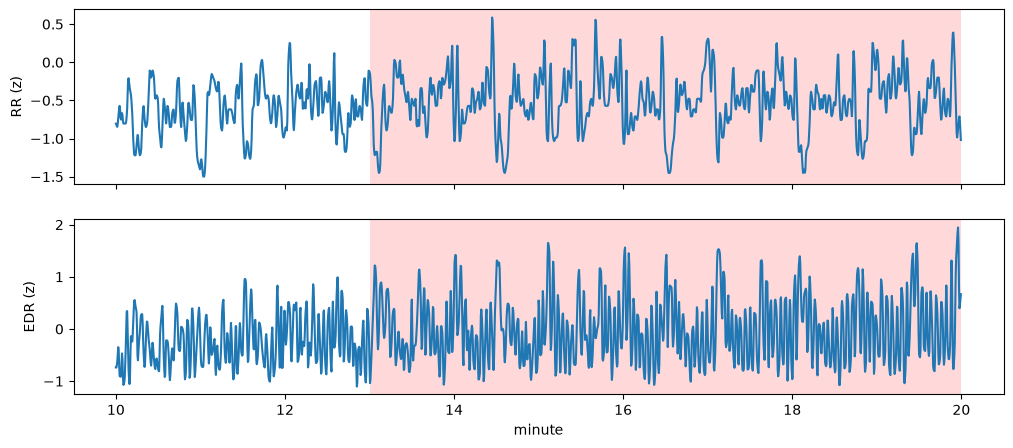

In [79]:
import matplotlib.pyplot as plt
d = np.load(ROOT / "data" / "processed" / "dl_cache" / "a01.npz")
rr, edr = d["rr_edr"]                 # two long arrays, 3 values per second
print(rr.shape, edr.shape)            # ~ (88,000,) each for an ~8 h night

lab = train[train.record == "a01"].set_index("minute").label
m0 = lab[lab == 1].index[0] - 3       # 3 min before the first apnea minute
s, e = m0 * 180, (m0 + 10) * 180      # 10 minutes = 1800 samples
t = np.arange(s, e) / 180             # in minutes

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(t, rr[s:e]); axes[0].set_ylabel("RR (z)")
axes[1].plot(t, edr[s:e]); axes[1].set_ylabel("EDR (z)")
for ax in axes:
    for m in lab.loc[m0:m0 + 9][lab == 1].index:
        ax.axvspan(m, m + 1, color="red", alpha=0.15, lw=0)
axes[1].set_xlabel("minute"); plt.show()